In [1]:
from collections import deque
from pathlib import Path

import ale_py
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.optim as optim
from torch import nn
from tqdm import tqdm

gym.register_envs(ale_py)

# Part-1

## Hyperparameters

In [2]:
LEARNING_RATE = 1e-3  # lowered from the assignment's 0.01, see the report
EPISODES = 2000
BATCH_EPISODES = (
    5  # episodes per optimizer step (lowers the gradient variance, not a baseline)
)
ENTROPY_COEF = 0.01  # entropy bonus that keeps the policy from saturating
MAX_GRAD_NORM = 1.0  # gradient clipping

GAMMA = 0.99  # discount factor (given by the assignment)

# The two allowed actions. ALE calls them RIGHT and LEFT; in Pong they move the paddle up and down.
UP, DOWN = 2, 3

EVAL_EPISODES = 500
MOVING_AVERAGE_WINDOW = 100
SEED = 0

CHECKPOINT_EVERY = 250  # the policy is saved every 250 episodes (used by Check 4)
RETRAIN = False  # False: load a finished run from CHECKPOINTS instead of training again (~80 min)

FIGURES = Path("report/figures")
CHECKPOINTS = Path("checkpoints/3b")

## Neural Net

In [3]:
class Policy(nn.Module):
    """Input: difference of two consecutive preprocessed frames (1x80x80). Output: logit of P(down)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, (3, 3), 1)
        self.conv2 = nn.Conv2d(8, 8, (3, 3), 1)
        self.relu = nn.ReLU()
        self.max_pool = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(8 * 18 * 18, 64)
        self.linear = nn.Linear(64, 1)

    def forward(self, x):
        x = self.max_pool(self.relu(self.conv1(x)))  # 78 -> 39
        x = self.max_pool(self.relu(self.conv2(x)))  # 37 -> 18
        x = self.flatten(x)
        x = self.relu(self.fc(x))
        x = self.linear(x)
        return x

## Training

In [4]:
def rewards_to_returns(rewards: list[float], gamma: float) -> torch.Tensor:
    """Discounted returns; the running return restarts after every point (reward != 0),
    so each action is only credited with the outcome of its own rally."""
    returns = deque()
    R = 0
    for reward in reversed(rewards):
        if reward != 0:
            R = 0
        R = reward + R * gamma
        returns.appendleft(R)

    return torch.Tensor(returns)


def preprocess(image) -> torch.Tensor:
    """prepro 210x160x3 uint8 frame into 6400 (80x80) 2D float array (given by the assignment).
    Returned as a 1x1x80x80 tensor. The frame is copied, so the environment's observation is not modified."""
    image = image[35:195]  # crop
    image = image[::2, ::2, 0].copy()  # downsample by factor of 2
    image[image == 144] = 0  # erase background (background type 1)
    image[image == 109] = 0  # erase background (background type 2)
    image[image != 0] = 1  # everything else (paddles, ball) just set to 1
    return torch.from_numpy(image.astype(np.float32)).view(1, 1, 80, 80)

In [5]:
def train(
    env: gym.Env,
    policy: nn.Module,
    optimizer: optim.Optimizer,
    episodes: int,
    gamma: float,
    batch_episodes: int = BATCH_EPISODES,
    entropy_coef: float = ENTROPY_COEF,
    seed: int | None = None,
    checkpoint_dir: Path | None = None,
) -> dict[str, np.ndarray]:
    """Train `policy` with REINFORCE (no baseline) and return a log with, per episode, the reward,
    the length and the mean and std of P(down), and the gradient norm (before clipping) of every update."""
    if episodes <= 0:
        raise ValueError(f"episodes must be positive, got {episodes}")
    if not 0 < gamma <= 1:
        raise ValueError(f"gamma must be in (0, 1], got {gamma}")
    if batch_episodes <= 0:
        raise ValueError(f"batch_episodes must be positive, got {batch_episodes}")

    log = {
        "reward": [],
        "length": [],
        "p_down_mean": [],
        "p_down_std": [],
        "grad_norm": [],
    }

    def save(name: str) -> None:
        if checkpoint_dir is not None:
            torch.save(policy.state_dict(), checkpoint_dir / f"policy_{name}.pt")
            np.savez(checkpoint_dir / "log.npz", **log)

    if checkpoint_dir is not None:
        checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save("0")

    policy.train()
    optimizer.zero_grad()
    progress = tqdm(range(episodes))
    for episode in progress:
        state, _ = env.reset(seed=seed if episode == 0 else None)
        prev = preprocess(state)
        done = False
        log_probs, entropies, p_down, rewards = [], [], [], []
        while not done:
            cur = preprocess(state)
            logit = policy(cur - prev)  # frame difference encodes the ball's motion
            prev = cur
            # logits instead of probs: the log-probability stays exact even when the policy saturates
            dist = torch.distributions.Bernoulli(logits=logit)
            action = dist.sample()

            state, reward, terminated, truncated, _ = env.step(
                DOWN if action.item() else UP
            )
            done = terminated or truncated

            log_probs.append(dist.log_prob(action))
            entropies.append(dist.entropy())
            p_down.append(dist.probs.item())
            rewards.append(reward)

        log_probs = torch.cat(log_probs).squeeze(-1)
        entropies = torch.cat(entropies).squeeze(-1)
        returns = rewards_to_returns(rewards, gamma)

        loss = -torch.sum(log_probs * returns) - entropy_coef * torch.sum(entropies)
        loss.backward()  # gradients accumulate over the batch of episodes

        if (episode + 1) % batch_episodes == 0 or episode == episodes - 1:
            grad_norm = nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM)
            log["grad_norm"].append(grad_norm.item())
            optimizer.step()
            optimizer.zero_grad()

        log["reward"].append(sum(rewards))
        log["length"].append(len(rewards))
        log["p_down_mean"].append(np.mean(p_down))
        log["p_down_std"].append(np.std(p_down))
        progress.set_postfix(
            reward=sum(rewards),
            length=len(rewards),
            p_down=f"{np.mean(p_down):.3f}",
            p_std=f"{np.std(p_down):.3f}",
        )
        if (episode + 1) % CHECKPOINT_EVERY == 0 or episode == episodes - 1:
            save(str(episode + 1))

    return {key: np.array(values) for key, values in log.items()}


def load_policy(name: str, episode: int) -> nn.Module:
    """The policy of run `name` after `episode` training episodes (0 = initial weights)."""
    policy = Policy()
    policy.load_state_dict(torch.load(CHECKPOINTS / name / f"policy_{episode}.pt"))
    return policy


def run_training(
    name: str,
    episodes: int = EPISODES,
    learning_rate: float = LEARNING_RATE,
    seed: int = SEED,
    **kwargs,
) -> tuple[nn.Module, dict[str, np.ndarray]]:
    """Train a fresh policy and save it to CHECKPOINTS / name. If that run already exists, load it instead (unless RETRAIN)."""
    directory = CHECKPOINTS / name
    if not RETRAIN and (directory / f"policy_{episodes}.pt").exists():
        print(
            f"Loading the finished run from {directory} (set RETRAIN = True to train again)"
        )
        return load_policy(name, episodes), dict(np.load(directory / "log.npz"))

    torch.manual_seed(seed)
    env = gym.make("ALE/Pong-v5")
    policy = Policy()
    optimizer = optim.Adam(policy.parameters(), lr=learning_rate)
    log = train(
        env,
        policy,
        optimizer,
        episodes,
        GAMMA,
        seed=seed,
        checkpoint_dir=directory,
        **kwargs,
    )
    env.close()
    return policy, log

## Evaluation and Plotting

In [6]:
# Values of the red channel in the raw frame
PLAYER_PADDLE, BALL = 92, 236


def positions(frame) -> tuple[float, float]:
    """Vertical centre (in pixels of the cropped frame) of the ball and of the player's paddle, NaN if not visible."""
    red = frame[
        35:193, :, 0
    ]  # the bottom border, which has the ball's colour, is cut off
    ball_rows = np.flatnonzero((red == BALL).any(axis=1))
    paddle_rows = np.flatnonzero((red == PLAYER_PADDLE).any(axis=1))
    return (
        ball_rows.mean() if ball_rows.size else np.nan,
        paddle_rows.mean() if paddle_rows.size else np.nan,
    )


def ball_x(frame) -> float:
    """Horizontal centre of the ball, NaN if not visible (the player's paddle is at x = 140-143)."""
    ball_cols = np.flatnonzero((frame[35:193, :, 0] == BALL).any(axis=0))
    return ball_cols.mean() if ball_cols.size else np.nan


def policy_act(policy: nn.Module):
    """P(down) of the trained network for a frame difference."""
    policy.eval()

    def act(diff: torch.Tensor, frame) -> float:
        with torch.no_grad():
            return torch.sigmoid(policy(diff)).item()

    return act


def rollout(
    env: gym.Env, act, seed: int, greedy: bool = False
) -> dict[str, np.ndarray]:
    """Play one episode. `act(diff, frame)` returns P(down); the action is sampled from it (or the more likely one if greedy).
    Returns, for every step, P(down), the action, the reward and the ball and paddle positions in the frame the action was chosen in.
    """
    state, _ = env.reset(seed=seed)
    prev = preprocess(state)
    steps = {
        "p_down": [],
        "action": [],
        "reward": [],
        "ball_y": [],
        "paddle_y": [],
        "ball_x": [],
    }
    done = False
    while not done:
        cur = preprocess(state)
        p_down = act(cur - prev, state)
        prev = cur
        down = p_down > 0.5 if greedy else torch.rand(1).item() < p_down
        ball_y, paddle_y = positions(state)
        frame_ball_x = ball_x(state)
        action = DOWN if down else UP

        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        for key, value in zip(
            steps, (p_down, action, reward, ball_y, paddle_y, frame_ball_x)
        ):
            steps[key].append(value)

    return {key: np.array(values) for key, values in steps.items()} | {
        "terminated": terminated
    }


def evaluate(
    act, episodes: int = EVAL_EPISODES, seed: int = SEED, greedy: bool = False
) -> list[dict[str, np.ndarray]]:
    """Roll out `act` for `episodes` episodes; episode i starts from seed + i."""
    env = gym.make("ALE/Pong-v5")
    torch.manual_seed(seed)  # only used when actions are sampled
    results = [
        rollout(env, act, seed + episode, greedy) for episode in tqdm(range(episodes))
    ]
    env.close()
    return results


def total_rewards(results: list[dict[str, np.ndarray]]) -> np.ndarray:
    return np.array([r["reward"].sum() for r in results])


def lengths(results: list[dict[str, np.ndarray]]) -> np.ndarray:
    return np.array([len(r["reward"]) for r in results])


def moving_average(values, window: int = MOVING_AVERAGE_WINDOW) -> np.ndarray:
    """Trailing moving average; the first window-1 entries average over fewer episodes."""
    cumsum = np.cumsum(np.insert(np.asarray(values, dtype=float), 0, 0.0))
    counts = np.minimum(np.arange(1, len(values) + 1), window)
    ends = np.arange(1, len(values) + 1)
    return (cumsum[ends] - cumsum[ends - counts]) / counts


def save_figure(fig: plt.Figure, name: str) -> None:
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"3b_{name}.png", dpi=150, bbox_inches="tight")


def plot_training(
    rewards, title: str, ax: plt.Axes | None = None, filename: str | None = None
) -> None:
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(rewards, alpha=0.4, label="Episode reward")
    ax.plot(
        moving_average(rewards),
        linewidth=2,
        label=f"Moving average ({MOVING_AVERAGE_WINDOW} episodes)",
    )
    ax.set(xlabel="Training episode", ylabel="Episode reward", title=title)
    ax.legend(loc="upper left")
    if standalone:
        if filename:
            save_figure(fig, filename)
        plt.show()


def plot_diagnostics(
    log: dict[str, np.ndarray], title: str, filename: str | None = None
) -> None:
    """Episode length, mean and std of P(down) per episode, and the gradient norm per update."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    panels = [
        ("length", "Episode length (steps)", None),
        ("p_down_mean", "Mean P(down) within the episode", (0, 1)),
        ("p_down_std", "Std of P(down) within the episode", None),
    ]
    for ax, (key, label, ylim) in zip(axes.flat, panels):
        ax.plot(log[key], alpha=0.4)
        ax.plot(moving_average(log[key]), linewidth=2)
        ax.set(xlabel="Training episode", ylabel=label, ylim=ylim)
    ax = axes.flat[3]
    updates = np.arange(1, len(log["grad_norm"]) + 1) * BATCH_EPISODES
    ax.plot(updates, log["grad_norm"])
    ax.axhline(
        MAX_GRAD_NORM,
        color="gray",
        linestyle=":",
        label=f"Clipping threshold ({MAX_GRAD_NORM})",
    )
    ax.set(
        xlabel="Training episode", ylabel="Gradient norm before clipping", yscale="log"
    )
    ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if filename:
        save_figure(fig, filename)
    plt.show()


def plot_histogram(
    eval_rewards: np.ndarray, title: str, filename: str | None = None
) -> None:
    mean, std = eval_rewards.mean(), eval_rewards.std()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(
        eval_rewards, bins=np.arange(eval_rewards.min() - 0.5, eval_rewards.max() + 1.5)
    )
    ax.axvline(
        mean, color="black", linestyle="--", label=f"Mean = {mean:.2f}, std = {std:.2f}"
    )
    ax.set(
        xlabel="Episode reward",
        ylabel="Number of episodes",
        title=f"{title}: {len(eval_rewards)} evaluation episodes",
    )
    ax.legend()
    if filename:
        save_figure(fig, filename)
    plt.show()
    print(f"{title}: mean = {mean:.2f}, std = {std:.2f}")


RESPONSE_EPISODES = 8
OFFSET = 10  # pixels between ball and paddle centre that count as "above" / "below"


def response(results: list[dict[str, np.ndarray]]) -> dict[str, float]:
    """Mean P(down) depending on the ball's vertical direction and on its position relative to the paddle."""
    p_down = np.concatenate([r["p_down"] for r in results])
    # motion between the previous and the current frame, i.e. what the frame difference shows (NaN while not visible)
    vy = np.concatenate([np.diff(r["ball_y"], prepend=np.nan) for r in results])
    vx = np.concatenate([np.diff(r["ball_x"], prepend=np.nan) for r in results])
    offset = np.concatenate([r["ball_y"] - r["paddle_y"] for r in results])
    approaching = vx > 0  # the player's paddle is on the right
    out = {
        "moving down": p_down[vy > 0].mean(),
        "moving up": p_down[vy < 0].mean(),
        "below": p_down[approaching & (offset > OFFSET)].mean(),
        "above": p_down[approaching & (offset < -OFFSET)].mean(),
    }
    out["direction gap"] = out["moving down"] - out["moving up"]
    out["position gap"] = out["below"] - out["above"]
    return out


## Training: REINFORCE without Baseline

$\gamma = 0.99$ (given by the assignment). Training takes about 80 minutes. The policy is saved every 250 episodes
to `checkpoints/3b/reinforce/`, together with the training log, so a crash does not lose the run. When the finished
run exists, this cell loads it instead of training again (`RETRAIN = False`).

Loading the finished run from checkpoints\3b\reinforce (set RETRAIN = True to train again)


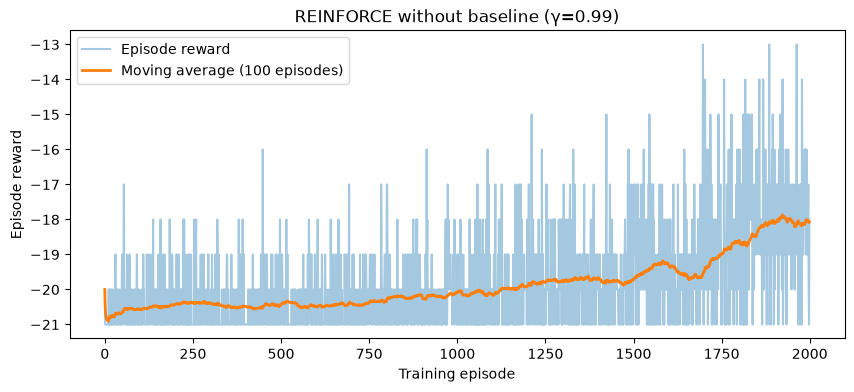

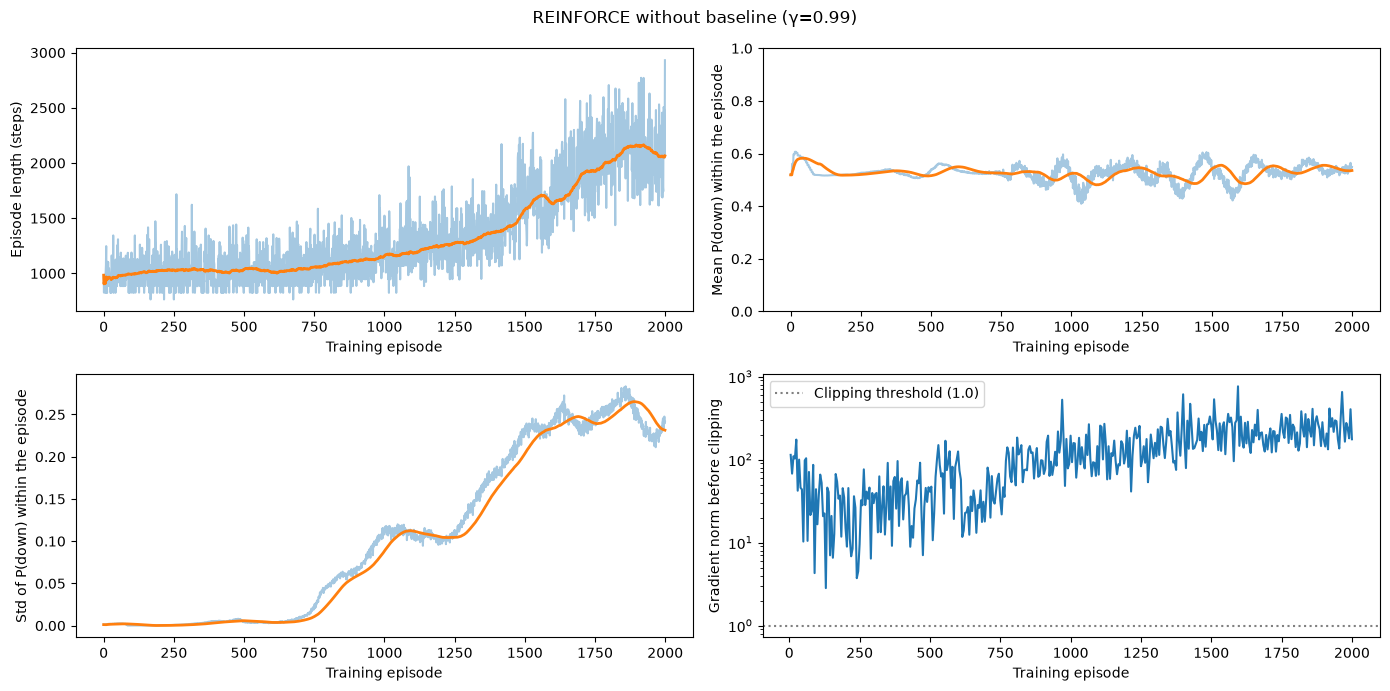

Mean reward: first 100 = -20.57, last 100 = -18.07
Mean length: first 100 = 993, last 100 = 2065
Std of P(down): first 100 = 0.0018, last 100 = 0.2314
Updates with gradient norm above 1.0 (clipped): 100%


In [7]:
NAME = "reinforce"
TITLE = "REINFORCE without baseline (γ=0.99)"

policy, log = run_training(NAME)
plot_training(log["reward"], TITLE, filename="training")
plot_diagnostics(log, TITLE, filename="training_diagnostics")

print(
    f"Mean reward: first 100 = {log['reward'][:100].mean():.2f}, last 100 = {log['reward'][-100:].mean():.2f}"
)
print(
    f"Mean length: first 100 = {log['length'][:100].mean():.0f}, last 100 = {log['length'][-100:].mean():.0f}"
)
print(
    f"Std of P(down): first 100 = {log['p_down_std'][:100].mean():.4f}, last 100 = {log['p_down_std'][-100:].mean():.4f}"
)
print(
    f"Updates with gradient norm above {MAX_GRAD_NORM} (clipped): {np.mean(log['grad_norm'] > MAX_GRAD_NORM):.0%}"
)

## Evaluation

500 episodes with actions **sampled** from the policy, as during training. Episode $i$ starts from seed $i$.
Sampling instead of the greedy action: while $P(\text{down})$ is still close to 0.5 everywhere, the greedy action
is decided by tiny differences and can turn into "almost always the same action" (compared in Check 3).
This takes about 10 minutes.

100%|██████████| 500/500 [23:15<00:00,  2.79s/it]


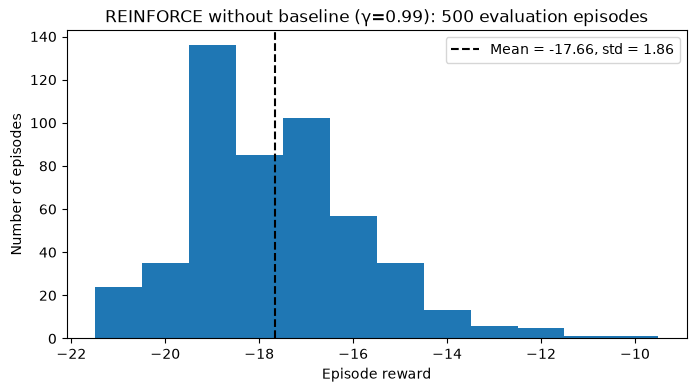

REINFORCE without baseline (γ=0.99): mean = -17.66, std = 1.86
Mean episode length: 2221 steps


In [8]:
eval_results = evaluate(policy_act(policy))
eval_rewards = total_rewards(eval_results)
np.save(
    CHECKPOINTS / NAME / "eval_rewards.npy", eval_rewards
)  # for the comparison with the baseline in Part 2
plot_histogram(eval_rewards, TITLE, filename="histogram")
print(f"Mean episode length: {lengths(eval_results).mean():.0f} steps")

## Checks

Each check prints `[PASS]` / `[FAIL]`. The checks reuse the trained policy and the evaluation episodes from above,
so none of them trains again (except two 2-episode trainings in the edge-case checks).

In [9]:
def report(name: str, passed: bool) -> None:
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

### Check 1: Returns and Credit Assignment

A point is scored only every few dozen steps, and all other rewards are 0. `rewards_to_returns` restarts the return
after every point, so each action is credited only with the outcome of its own rally. **Expected:**
- A single reward at the end gives $G_t = \gamma^{T-1-t}$.
- With two rallies, the actions of the first rally only see the first point: `[0, 0, -1, 0, 0, +1]` gives
  $[-\gamma^2, -\gamma, -1, \gamma^2, \gamma, 1]$.
- Therefore $|G_t| \le 1$ for every step of a real episode.

[PASS] A single final reward is worth γ^(T-1-t)
[PASS] Each rally only sees its own point: [0, 0, -1, 0, 0, +1] -> [-γ², -γ, -1, γ², γ, 1]
[PASS] |G_t| <= 1 in a real episode (2837 steps)
Rally length: median 95 steps, γ^median = 0.38


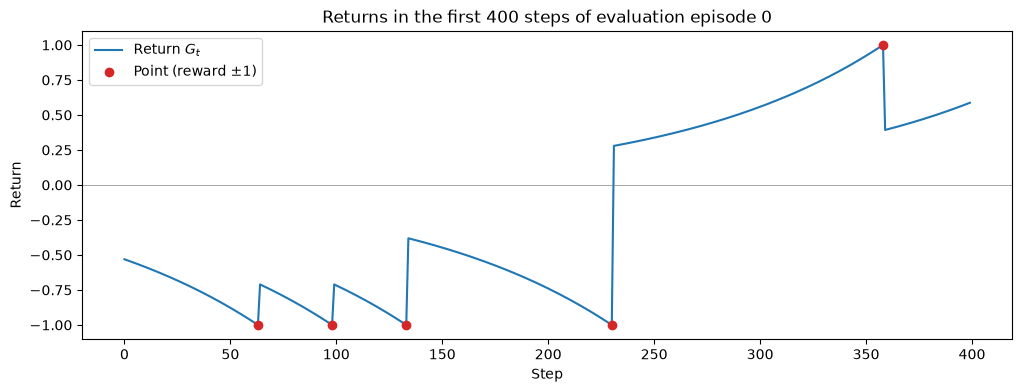

In [10]:
T = 200
t = np.arange(T)
report(
    "A single final reward is worth γ^(T-1-t)",
    np.allclose(
        rewards_to_returns([0.0] * (T - 1) + [1.0], GAMMA).numpy(),
        GAMMA ** (T - 1 - t),
        rtol=1e-4,
    ),
)
g = GAMMA
report(
    "Each rally only sees its own point: [0, 0, -1, 0, 0, +1] -> [-γ², -γ, -1, γ², γ, 1]",
    np.allclose(
        rewards_to_returns([0, 0, -1, 0, 0, 1], GAMMA).numpy(),
        [-(g**2), -g, -1, g**2, g, 1],
    ),
)
episode = eval_results[0]
returns = rewards_to_returns(list(episode["reward"]), GAMMA).numpy()
report(
    f"|G_t| <= 1 in a real episode ({len(returns)} steps)",
    np.all(np.abs(returns) <= 1 + 1e-6),
)

rally_lengths = np.diff(np.flatnonzero(np.concatenate([[1], episode["reward"]])))
print(
    f"Rally length: median {np.median(rally_lengths):.0f} steps, γ^median = {GAMMA ** np.median(rally_lengths):.2f}"
)

fig, ax = plt.subplots(figsize=(12, 4))
steps = slice(0, 400)
ax.plot(np.arange(len(returns))[steps], returns[steps], label="Return $G_t$")
points = np.flatnonzero(episode["reward"][steps])
ax.scatter(
    points,
    episode["reward"][steps][points],
    color="C3",
    zorder=3,
    label="Point (reward ±1)",
)
ax.axhline(0, color="gray", linewidth=0.5)
ax.set(
    xlabel="Step",
    ylabel="Return",
    title="Returns in the first 400 steps of evaluation episode 0",
)
ax.legend()
save_figure(fig, "returns")
plt.show()

### Check 2: Preprocessing, Frame Difference and Actions

The network only sees the difference of two consecutive preprocessed frames. **Expected:**
- The preprocessed frame contains only 0 and 1 (background vs. paddles and ball), the difference only −1, 0 and 1.
- In the difference, static objects disappear and moving objects (ball, paddles) show up as a +1/−1 pair, which
  encodes the direction of motion. In the first step of an episode, the difference is all 0.
- `preprocess` does not modify the environment's observation.
- Action 2 (`UP`) moves the player's paddle to the top, action 3 (`DOWN`) to the bottom.

[PASS] First step: the frame difference is all 0
[PASS] preprocess does not modify the observation
[PASS] Preprocessed frame contains only 0 and 1
[PASS] Frame difference contains only -1, 0 and 1


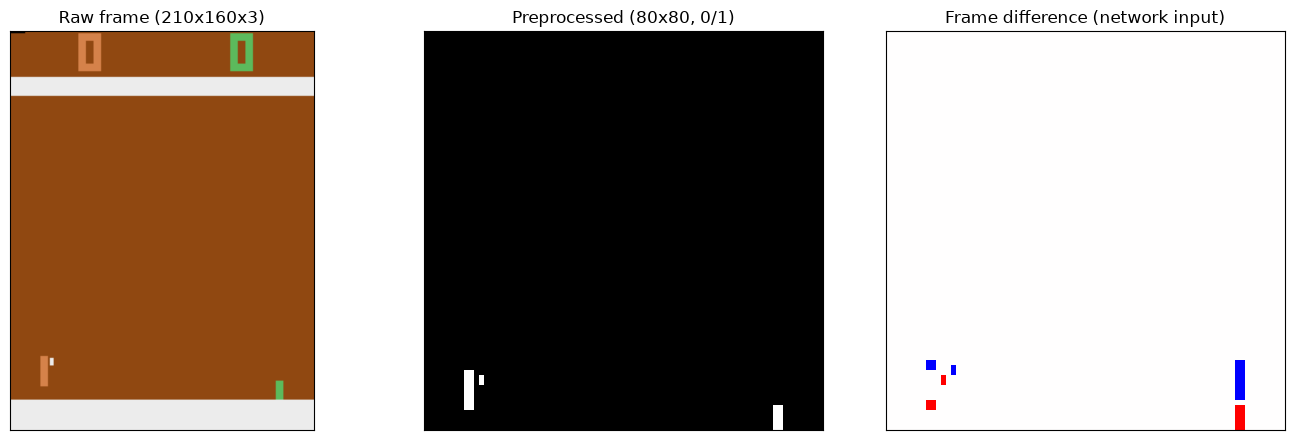

[PASS] Action 2 (UP) moves the paddle to the top (y = 2 of 158)
[PASS] Action 3 (DOWN) moves the paddle to the bottom (y = 156 of 158)


In [11]:
env = gym.make("ALE/Pong-v5", repeat_action_probability=0.0)
state, _ = env.reset(seed=SEED)
first = preprocess(state)
report(
    "First step: the frame difference is all 0", torch.all(first - first == 0).item()
)

visible_for = 0
for step in range(1000):  # play until the ball has been in play for a few steps
    previous_state = state
    state, *_ = env.step(DOWN if step % 20 < 10 else UP)
    visible_for = visible_for + 1 if not np.isnan(positions(state)[0]) else 0
    if visible_for == 15:
        break
original = state.copy()
prev, cur = preprocess(previous_state), preprocess(state)
diff = cur - prev
report("preprocess does not modify the observation", np.array_equal(state, original))
report(
    "Preprocessed frame contains only 0 and 1", set(cur.unique().tolist()) <= {0.0, 1.0}
)
report(
    "Frame difference contains only -1, 0 and 1",
    set(diff.unique().tolist()) <= {-1.0, 0.0, 1.0},
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(state)
axes[0].set_title("Raw frame (210x160x3)")
axes[1].imshow(cur[0, 0], cmap="gray")
axes[1].set_title("Preprocessed (80x80, 0/1)")
axes[2].imshow(diff[0, 0], cmap="bwr", vmin=-1, vmax=1)
axes[2].set_title("Frame difference (network input)")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()
save_figure(fig, "preprocessing")
plt.show()

for action, label, at_top in ((UP, "UP", True), (DOWN, "DOWN", False)):
    state, _ = env.reset(seed=SEED)
    for _ in range(20):
        state, *_ = env.step(action)
    _, paddle_y = positions(state)
    report(
        f"Action {action} ({label}) moves the paddle to the {'top' if at_top else 'bottom'} (y = {paddle_y:.0f} of 158)",
        paddle_y < 20 if at_top else paddle_y > 138,
    )
env.close()

### Check 3: Comparison with Reference Policies

Four fixed policies on the same start states (50 episodes each):
- **Random:** up or down with probability 0.5 each, i.e. an untrained policy.
- **Always up / always down:** the paddle stays at the edge, the simplest way to lose every rally.
- **Ball tracker:** moves the paddle towards the ball (hand-coded from the pixel positions). It shows what the
  two actions can achieve when the policy reacts to the ball.

**Expected:** always up/down give exactly −21 in the shortest episodes, random is slightly better, and the tracker
plays much longer rallies. The trained policy should be at least as good as random. Its greedy version is also
evaluated here.

100%|██████████| 50/50 [03:05<00:00,  3.71s/it]


Policy                                      Reward    Length  Points won
Always up                            -21.00 ± 0.00       764        0.00
Always down                          -21.00 ± 0.00       764        0.00
Random                               -20.40 ± 0.75      1024        0.60
Ball tracker                         -14.74 ± 2.16      3876        6.26
Trained, sampled (as evaluated)      -18.02 ± 1.83      2217        2.98
Trained, greedy                      -15.68 ± 2.37      2960        5.32
[PASS] Always up/down lose every point (-21)
[PASS] Random is better than always up/down
[PASS] The ball tracker beats random
[PASS] Trained policy (sampled, 500 episodes) is at least as good as random


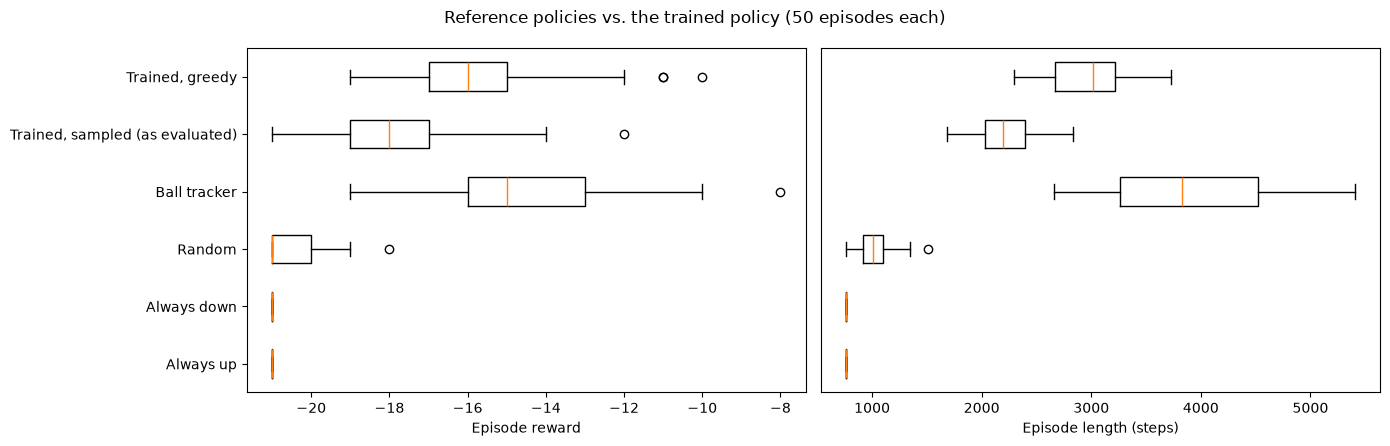

In [12]:
REFERENCE_EPISODES = 50


def tracker(diff, frame) -> float:
    ball_y, paddle_y = positions(frame)
    if np.isnan(ball_y) or np.isnan(paddle_y):
        return 0.5
    return float(ball_y > paddle_y)


references = {
    "Always up": lambda diff, frame: 0.0,
    "Always down": lambda diff, frame: 1.0,
    "Random": lambda diff, frame: 0.5,
    "Ball tracker": tracker,
}
reference_results = {
    name: evaluate(act, episodes=REFERENCE_EPISODES) for name, act in references.items()
}
reference_results["Trained, sampled (as evaluated)"] = eval_results[:REFERENCE_EPISODES]
reference_results["Trained, greedy"] = evaluate(
    policy_act(policy), episodes=REFERENCE_EPISODES, greedy=True
)

print(f"{'Policy':<34}{'Reward':>16}{'Length':>10}{'Points won':>12}")
for name, results in reference_results.items():
    rewards = total_rewards(results)
    won = np.mean([np.sum(r["reward"] == 1) for r in results])
    print(
        f"{name:<34}{rewards.mean():>9.2f} ± {rewards.std():<4.2f}{lengths(results).mean():>10.0f}{won:>12.2f}"
    )

reward_of = {
    name: total_rewards(results).mean() for name, results in reference_results.items()
}
report(
    "Always up/down lose every point (-21)",
    reward_of["Always up"] == reward_of["Always down"] == -21,
)
report("Random is better than always up/down", reward_of["Random"] > -21)
report("The ball tracker beats random", reward_of["Ball tracker"] > reward_of["Random"])
report(
    f"Trained policy (sampled, {EVAL_EPISODES} episodes) is at least as good as random",
    eval_rewards.mean() >= reward_of["Random"],
)

fig, (ax_r, ax_l) = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(reference_results)
for ax, values, label in (
    (ax_r, [total_rewards(r) for r in reference_results.values()], "Episode reward"),
    (ax_l, [lengths(r) for r in reference_results.values()], "Episode length (steps)"),
):
    ax.boxplot(values, tick_labels=names, orientation="horizontal")
    ax.set(xlabel=label)
ax_l.set(yticks=[])
fig.suptitle(
    f"Reference policies vs. the trained policy ({REFERENCE_EPISODES} episodes each)"
)
fig.tight_layout()
save_figure(fig, "reference_policies")
plt.show()

### Check 4: Does the Policy React to the Ball?

For the saved policies after 0, 250, …, 2000 episodes, I play 8 episodes each and measure how much $P(\text{down})$
depends on two features of the ball:
- **Direction gap:** $P(\text{down} \mid \text{ball moving down}) - P(\text{down} \mid \text{ball moving up})$.
  The vertical motion is directly visible in the frame difference (a +1/−1 pair).
- **Position gap:** $P(\text{down} \mid \text{ball below the paddle}) - P(\text{down} \mid \text{ball above the paddle})$
  (by more than 10 pixels), only while the ball comes towards the player, when the action matters. The paddle only
  shows up in the frame difference while it moves, so its position is harder to see.

Both gaps are 0 for a policy that ignores the ball and positive for one that moves with or towards it. I use gaps
instead of correlations: while $P(\text{down})$ barely varies, a correlation only measures noise.
**Expected:**
- Initial policy: both gaps ≈ 0.
- The direction gap grows during training. The position gap, if at all, grows later.

100%|██████████| 8/8 [00:22<00:00,  2.84s/it]


Checkpoint   P(down): ball down / up  Direction gap   P(down): below / above  Position gap
         0           0.519 / 0.519         -0.000          0.519 / 0.519        -0.000
       250           0.527 / 0.527         +0.000          0.527 / 0.527        -0.000
       500           0.541 / 0.538         +0.003          0.540 / 0.539        +0.001
       750           0.537 / 0.511         +0.026          0.530 / 0.514        +0.015
      1000           0.553 / 0.458         +0.095          0.485 / 0.512        -0.027
      1250           0.564 / 0.487         +0.077          0.528 / 0.520        +0.008
      1500           0.605 / 0.516         +0.089          0.516 / 0.590        -0.073
      1750           0.564 / 0.478         +0.085          0.518 / 0.517        +0.001
      2000           0.607 / 0.522         +0.085          0.531 / 0.588        -0.057


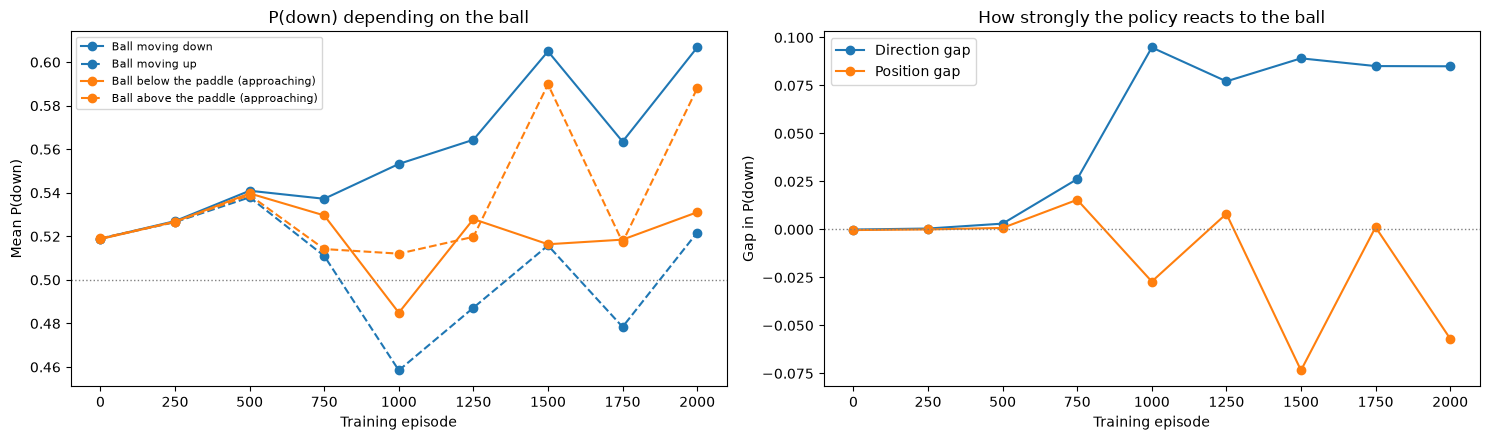

[PASS] Initial policy ignores the ball (|gaps| < 0.02: -0.000, -0.000)
[PASS] Final policy moves with the ball's vertical direction (direction gap +0.085 > 0.05)
[FAIL] Final policy moves towards the ball while it approaches (position gap -0.057 > 0.05)


In [13]:
checkpoints = list(range(0, EPISODES + 1, CHECKPOINT_EVERY))
responses = {
    episode: response(
        evaluate(policy_act(load_policy(NAME, episode)), episodes=RESPONSE_EPISODES)
    )
    for episode in checkpoints
}

print(
    f"{'Checkpoint':>10}{'P(down): ball down / up':>26}{'Direction gap':>15}{'P(down): below / above':>25}{'Position gap':>14}"
)
for episode, r in responses.items():
    print(
        f"{episode:>10}{r['moving down']:>16.3f} / {r['moving up']:.3f}{r['direction gap']:>+15.3f}"
        f"{r['below']:>15.3f} / {r['above']:.3f}{r['position gap']:>+14.3f}"
    )

fig, (ax_p, ax_gap) = plt.subplots(1, 2, figsize=(15, 4.5))
lines = {
    "moving down": ("C0", "-", "Ball moving down"),
    "moving up": ("C0", "--", "Ball moving up"),
    "below": ("C1", "-", "Ball below the paddle (approaching)"),
    "above": ("C1", "--", "Ball above the paddle (approaching)"),
}
for key, (color, style, label) in lines.items():
    ax_p.plot(
        checkpoints,
        [r[key] for r in responses.values()],
        color=color,
        linestyle=style,
        marker="o",
        label=label,
    )
ax_p.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax_p.set(
    xlabel="Training episode",
    ylabel="Mean P(down)",
    title="P(down) depending on the ball",
)
ax_p.legend(fontsize=8)
for key, color in (("direction gap", "C0"), ("position gap", "C1")):
    ax_gap.plot(
        checkpoints,
        [r[key] for r in responses.values()],
        color=color,
        marker="o",
        label=key.capitalize(),
    )
ax_gap.axhline(0, color="gray", linestyle=":", linewidth=1)
ax_gap.set(
    xlabel="Training episode",
    ylabel="Gap in P(down)",
    title="How strongly the policy reacts to the ball",
)
ax_gap.legend()
fig.tight_layout()
save_figure(fig, "policy_response")
plt.show()

initial, final = responses[0], responses[EPISODES]
report(
    f"Initial policy ignores the ball (|gaps| < 0.02: {initial['direction gap']:+.3f}, {initial['position gap']:+.3f})",
    abs(initial["direction gap"]) < 0.02 and abs(initial["position gap"]) < 0.02,
)
report(
    f"Final policy moves with the ball's vertical direction (direction gap {final['direction gap']:+.3f} > 0.05)",
    final["direction gap"] > 0.05,
)
report(
    f"Final policy moves towards the ball while it approaches (position gap {final['position gap']:+.3f} > 0.05)",
    final["position gap"] > 0.05,
)

### Check 5: First 10 Steps

The last 10 steps before the first point of evaluation episode 0, i.e. while the ball approaches the player's paddle.
**Expected:** if the policy has learned to follow the ball, the more likely action (P(down) > 0.5 → down) mostly
points towards the ball.

In [14]:
FIRST_STEPS = 10

episode = eval_results[0]
end = np.flatnonzero(episode["reward"])[0] + 1
window = slice(end - FIRST_STEPS, end)
print(
    f"{'t':>4}{'ball y':>8}{'paddle y':>10}{'offset':>8}{'P(down)':>9}{'action':>8}{'reward':>8}"
)
towards_ball = []
for step in range(window.start, window.stop):
    ball_y, paddle_y, p_down = (
        episode["ball_y"][step],
        episode["paddle_y"][step],
        episode["p_down"][step],
    )
    action = "down" if episode["action"][step] == DOWN else "up"
    print(
        f"{step:>4}{ball_y:>8.1f}{paddle_y:>10.1f}{ball_y - paddle_y:>8.1f}{p_down:>9.3f}{action:>8}{episode['reward'][step]:>8.0f}"
    )
    if not np.isnan(ball_y - paddle_y):
        towards_ball.append((p_down > 0.5) == (ball_y > paddle_y))
report(
    f"The more likely action points towards the ball in {sum(towards_ball)}/{len(towards_ball)} steps",
    sum(towards_ball) > len(towards_ball) / 2,
)

   t  ball y  paddle y  offset  P(down)  action  reward
  54    49.5     128.5   -79.0    0.243      up       0
  55    57.5     110.5   -53.0    0.213    down       0
  56    65.5     108.5   -43.0    0.316      up       0
  57    73.0     104.5   -31.5    0.558    down       0
  58    80.5     106.5   -26.0    0.616    down       0
  59    88.5     124.5   -36.0    0.618    down       0
  60    96.5     146.5   -50.0    0.670      up       0
  61   104.5     148.5   -44.0    0.686      up       0
  62   112.5     132.5   -20.0    0.602    down       0
  63   120.5     130.5   -10.0    0.745    down      -1
[FAIL] The more likely action points towards the ball in 3/10 steps


### Edge-Case Checks
- **Invalid inputs:** `episodes <= 0`, $\gamma \notin (0, 1]$ and `batch_episodes <= 0` are rejected with a `ValueError`.
- **Saturated policy:** with `Bernoulli(probs=sigmoid(logit))`, PyTorch clamps the probability, so the
  log-probability of the unlikely action is wrong (−15.9 instead of −50 for a logit of 50). With `logits=` it is exact.
- **End of an episode:** Pong-v5 has no step limit that matters (108,000 frames = 27,000 steps), so every episode
  must end because one side reached 21 points, never by truncation.
- **Sticky actions:** Pong-v5 repeats the previous action with probability 0.25, so the same seed and the same actions
  do not give identical games unless the environment is seeded. Training twice with the same seed must give identical results.

In [15]:
env = gym.make("ALE/Pong-v5")
for label, kwargs in {
    "episodes = 0": {"episodes": 0, "gamma": GAMMA},
    "γ = 0": {"episodes": 1, "gamma": 0.0},
    "γ = 1.5": {"episodes": 1, "gamma": 1.5},
    "batch_episodes = 0": {"episodes": 1, "gamma": GAMMA, "batch_episodes": 0},
}.items():
    try:
        train(env, Policy(), optim.Adam(Policy().parameters()), **kwargs)
        raised = False
    except ValueError:
        raised = True
    report(f"Rejects {label}", raised)

logit = torch.tensor([50.0])
with_probs = (
    torch.distributions.Bernoulli(probs=torch.sigmoid(logit))
    .log_prob(torch.tensor([0.0]))
    .item()
)
with_logits = (
    torch.distributions.Bernoulli(logits=logit).log_prob(torch.tensor([0.0])).item()
)
print(
    f"log P(up) at logit 50: probs = {with_probs:.2f}, logits = {with_logits:.2f} (exact: -50)"
)
report(
    "logits= gives the exact log-probability of a saturated policy",
    np.isclose(with_logits, -50.0),
)

all_results = eval_results + [
    r for results in reference_results.values() for r in results
]
report(
    f"All {len(all_results)} evaluation episodes end by termination, never by truncation",
    all(r["terminated"] for r in all_results),
)
report(
    "Every episode ends when one side has 21 points",
    all(
        max(np.sum(r["reward"] == 1), np.sum(r["reward"] == -1)) == 21
        for r in all_results
    ),
)


def short_run() -> np.ndarray:
    torch.manual_seed(SEED)
    policy = Policy()
    return train(
        env,
        policy,
        optim.Adam(policy.parameters(), lr=LEARNING_RATE),
        2,
        GAMMA,
        batch_episodes=1,
        seed=SEED,
    )


first, second = short_run(), short_run()
report(
    "Same seed gives identical training (rewards, lengths and P(down))",
    all(np.array_equal(first[key], second[key]) for key in first),
)
env.close()

[PASS] Rejects episodes = 0
[PASS] Rejects γ = 0
[PASS] Rejects γ = 1.5
[PASS] Rejects batch_episodes = 0
log P(up) at logit 50: probs = -15.94, logits = -50.00 (exact: -50)
[PASS] logits= gives the exact log-probability of a saturated policy
[PASS] All 800 evaluation episodes end by termination, never by truncation
[PASS] Every episode ends when one side has 21 points


100%|██████████| 2/2 [00:04<00:00,  2.23s/it, length=1104, p_down=0.541, p_std=0.001, reward=-20]

[PASS] Same seed gives identical training (rewards, lengths and P(down))


# Part 2: REINFORCE With a Learned Baseline (Actor-Critic)

**Setup.** Everything is identical to Part 1: network, frame difference, $\gamma = 0.99$, return restart after every point,
learning rate 0.001, 5 episodes per update, entropy bonus, clipping, 2,000 episodes and seed 0. The only change is the weight
of the log-probabilities: the **advantage** $A_t = G_t - V(s_t)$ instead of the return $G_t$. $V$ is a second network, the
*critic*, which learns to predict the return.

**Baseline.**
- **Critic:** same layers as the policy, trained on the same Monte-Carlo returns with the mean squared error
  $\frac{1}{T}\sum_t (V(s_t) - G_t)^2$ and its own Adam optimizer (learning rate 0.001, clipped to norm 1).
- **Unbiased:** the advantage uses the Monte-Carlo return $G_t$, not a bootstrapped TD target, and $V(s_t)$ does not depend
  on the action $a_t$. So the expected gradient is the same as in Part 1; only its variance changes.
- **Critic input:** the current frame **and** the frame difference (2×80×80). The value of a state depends on where the
  paddle is relative to the ball, which the frame difference alone mostly hides (Part 1, Check 4). Any input that does not
  depend on $a_t$ keeps the baseline unbiased.
- **Detached:** $V$ is a constant in the actor's loss, so the actor's loss does not train the critic.
- **Same start:** same seed and same initial actor weights as Part 1. The critic is initialised without consuming the random
  numbers used for sampling, so the first batch of 5 episodes is identical to Part 1 (Check 6).

**Plan.**
1. Train once (seed 0) and evaluate on 500 sampled episodes, as in Part 1; also 50 greedy episodes for both runs.
2. **Comparison** with Part 1 (loaded from `checkpoints/3b/reinforce/`): training curves, moving averages, histograms, a table,
   the critic's learning curves and the policy's response to the ball.
3. **Checks:** the setup and the advantage computation, the critic's predictions, the variance of the gradient estimate with
   and without baseline, and edge cases.

Runtime: training about 2 h (episodes get longer as the policy improves), evaluation about 20 min, checks about 25 min.
The run is saved to `checkpoints/3b/actor_critic/`, and all evaluations and checks are cached there, so with
`RETRAIN = False` and `RECOMPUTE = False` the whole Part 2 runs again in seconds. Part 2 only needs the definition cells of
Part 1 (up to *Evaluation and Plotting*) and the `report` helper of the Checks section, not the Part 1 training.

## Hyperparameters and Helpers

In [16]:
import pickle

PART1_NAME = "reinforce"  # the Part 1 run, loaded from CHECKPOINTS
AC_NAME = "actor_critic"
RUN_TITLES = {"Without baseline": PART1_NAME, "With baseline (actor-critic)": AC_NAME}

CRITIC_LEARNING_RATE = 1e-3
VALUE_CHUNK = 256  # steps per forward/backward pass of the critic (limits the memory for long episodes)

GREEDY_EPISODES = 50  # greedy evaluation of both runs (as in Check 3)
VALUE_EPISODES = 10  # episodes for the value-prediction check (Check 7)
GRADIENT_BATCHES = (
    20  # batches of BATCH_EPISODES episodes for the gradient-variance check (Check 8)
)
REWARD_LEVEL = (
    -19.5
)  # "learning speed": first episode at which the moving average reaches this reward
CHECKPOINT_EPISODES = list(range(0, EPISODES + 1, CHECKPOINT_EVERY))

RECOMPUTE = False  # False: load cached evaluations and checks from CHECKPOINTS instead of computing them again


def cached(name: str, compute):
    """`compute()`, saved to CHECKPOINTS / AC_NAME / f"{name}.pkl" and loaded from there next time (unless RECOMPUTE)."""
    path = CHECKPOINTS / AC_NAME / f"{name}.pkl"
    if path.exists() and not RECOMPUTE:
        with open(path, "rb") as file:
            return pickle.load(file)
    result = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as file:
        pickle.dump(result, file)
    return result


def summary(results: list[dict[str, np.ndarray]]) -> dict[str, np.ndarray]:
    """Reward, length and points won of every evaluation episode (the step data is not kept)."""
    return {
        "reward": total_rewards(results),
        "length": lengths(results),
        "won": np.array([np.sum(r["reward"] == 1) for r in results]),
    }

## Critic Network

In [17]:
class Critic(nn.Module):
    """State-value network V(s). Input: current preprocessed frame and frame difference (2x80x80). Output: V(s).
    Same layers as the policy, apart from the second input channel."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(2, 8, (3, 3), 1)
        self.conv2 = nn.Conv2d(8, 8, (3, 3), 1)
        self.relu = nn.ReLU()
        self.max_pool = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(8 * 18 * 18, 64)
        self.linear = nn.Linear(64, 1)

    def forward(self, x):
        x = self.max_pool(self.relu(self.conv1(x)))  # 78 -> 39
        x = self.max_pool(self.relu(self.conv2(x)))  # 37 -> 18
        x = self.flatten(x)
        x = self.relu(self.fc(x))
        return self.linear(x).squeeze(-1)


def critic_input(cur: torch.Tensor, prev: torch.Tensor) -> torch.Tensor:
    """Current frame and frame difference as a 1x2x80x80 tensor. All values are -1, 0 or 1, so int8 saves memory."""
    return torch.cat([cur, cur - prev], dim=1).to(torch.int8)

## Training With the Critic

In [18]:
def sample_episode(env: gym.Env, policy: nn.Module, seed: int | None = None) -> dict:
    """Play one episode with actions sampled from `policy`, exactly as in Part 1's `train`. Returns the log-probabilities and
    entropies (with graph), P(down), the rewards and the critic input of every step."""
    state, _ = env.reset(seed=seed)
    prev = preprocess(state)
    done = False
    steps = {
        "log_probs": [],
        "entropies": [],
        "p_down": [],
        "rewards": [],
        "inputs": [],
    }
    while not done:
        cur = preprocess(state)
        logit = policy(cur - prev)  # the actor sees the frame difference, as in Part 1
        steps["inputs"].append(critic_input(cur, prev))
        prev = cur
        dist = torch.distributions.Bernoulli(logits=logit)
        action = dist.sample()

        state, reward, terminated, truncated, _ = env.step(
            DOWN if action.item() else UP
        )
        done = terminated or truncated

        steps["log_probs"].append(dist.log_prob(action))
        steps["entropies"].append(dist.entropy())
        steps["p_down"].append(dist.probs.item())
        steps["rewards"].append(reward)

    return {
        "log_probs": torch.cat(steps["log_probs"]).squeeze(-1),
        "entropies": torch.cat(steps["entropies"]).squeeze(-1),
        "p_down": np.array(steps["p_down"]),
        "rewards": steps["rewards"],
        "inputs": torch.cat(steps["inputs"]),
    }


def critic_values(
    critic: nn.Module,
    inputs: torch.Tensor,
    returns: torch.Tensor | None = None,
    chunk: int = VALUE_CHUNK,
) -> tuple[torch.Tensor, float]:
    """V(s_t) for all steps of an episode, in chunks of `chunk` steps. If `returns` are given, the gradient of the critic's
    loss (1/T) Σ_t (V(s_t) - G_t)² is accumulated. Returns the values (without gradient) and the loss."""
    values, total_loss = [], 0.0
    for start in range(0, len(inputs), chunk):
        batch = inputs[start : start + chunk].float()
        if returns is None:
            with torch.no_grad():
                values.append(critic(batch))
            continue
        v = critic(batch)
        loss = ((v - returns[start : start + chunk]) ** 2).sum() / len(inputs)
        loss.backward()
        total_loss += loss.item()
        values.append(v.detach())
    return torch.cat(values), total_loss


def explained_variance(returns: torch.Tensor, values: torch.Tensor) -> float:
    """1 - Var(G - V) / Var(G): 1 for a perfect critic, 0 for one that only predicts the mean, < 0 for a worse one."""
    return (1 - (returns - values).var() / returns.var()).item()


def train_actor_critic(
    env: gym.Env,
    policy: nn.Module,
    critic: nn.Module,
    optimizer: optim.Optimizer,
    critic_optimizer: optim.Optimizer,
    episodes: int,
    gamma: float,
    batch_episodes: int = BATCH_EPISODES,
    entropy_coef: float = ENTROPY_COEF,
    seed: int | None = None,
    checkpoint_dir: Path | None = None,
) -> dict[str, np.ndarray]:
    """Part 1's `train` with one change: the actor is weighted with the advantage G_t - V(s_t) instead of the return G_t,
    and the critic V is trained on the same returns. Returns the log of `train`, plus per episode the critic's loss, its
    explained variance and the mean |advantage| and |return|, and per update the critic's gradient norm."""
    if episodes <= 0:
        raise ValueError(f"episodes must be positive, got {episodes}")
    if not 0 < gamma <= 1:
        raise ValueError(f"gamma must be in (0, 1], got {gamma}")
    if batch_episodes <= 0:
        raise ValueError(f"batch_episodes must be positive, got {batch_episodes}")
    optimized = {
        id(p) for group in critic_optimizer.param_groups for p in group["params"]
    }
    if optimized != {id(p) for p in critic.parameters()}:
        raise ValueError(
            "critic_optimizer must optimize exactly the parameters of the critic"
        )

    keys = [
        "reward",
        "length",
        "p_down_mean",
        "p_down_std",
        "value_loss",
        "explained_variance",
        "advantage_abs",
        "return_abs",
        "grad_norm",
        "critic_grad_norm",
    ]
    log = {key: [] for key in keys}

    def save(name: str) -> None:
        if checkpoint_dir is not None:
            torch.save(policy.state_dict(), checkpoint_dir / f"policy_{name}.pt")
            torch.save(critic.state_dict(), checkpoint_dir / f"critic_{name}.pt")
            np.savez(checkpoint_dir / "log.npz", **log)

    if checkpoint_dir is not None:
        checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save("0")

    policy.train()
    critic.train()
    optimizer.zero_grad()
    critic_optimizer.zero_grad()
    progress = tqdm(range(episodes))
    for episode in progress:
        sample = sample_episode(env, policy, seed=seed if episode == 0 else None)
        returns = rewards_to_returns(sample["rewards"], gamma)
        values, value_loss = critic_values(
            critic, sample["inputs"], returns
        )  # also accumulates the critic's gradient
        advantages = (
            returns - values
        )  # the values carry no gradient: the actor's loss does not train the critic

        loss = -torch.sum(sample["log_probs"] * advantages) - entropy_coef * torch.sum(
            sample["entropies"]
        )
        loss.backward()  # gradients accumulate over the batch of episodes

        if (episode + 1) % batch_episodes == 0 or episode == episodes - 1:
            log["grad_norm"].append(
                nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM).item()
            )
            log["critic_grad_norm"].append(
                nn.utils.clip_grad_norm_(critic.parameters(), MAX_GRAD_NORM).item()
            )
            optimizer.step()
            critic_optimizer.step()
            optimizer.zero_grad()
            critic_optimizer.zero_grad()

        rewards, p_down = sample["rewards"], sample["p_down"]
        log["reward"].append(sum(rewards))
        log["length"].append(len(rewards))
        log["p_down_mean"].append(p_down.mean())
        log["p_down_std"].append(p_down.std())
        log["value_loss"].append(value_loss)
        log["explained_variance"].append(explained_variance(returns, values))
        log["advantage_abs"].append(advantages.abs().mean().item())
        log["return_abs"].append(returns.abs().mean().item())
        progress.set_postfix(
            reward=sum(rewards),
            length=len(rewards),
            p_std=f"{p_down.std():.3f}",
            explained_var=f"{log['explained_variance'][-1]:.2f}",
        )
        if (episode + 1) % CHECKPOINT_EVERY == 0 or episode == episodes - 1:
            save(str(episode + 1))

    return {key: np.array(values) for key, values in log.items()}


def load_critic(name: str, episode: int) -> nn.Module:
    """The critic of run `name` after `episode` training episodes (0 = initial weights)."""
    critic = Critic()
    critic.load_state_dict(torch.load(CHECKPOINTS / name / f"critic_{episode}.pt"))
    return critic


def run_actor_critic(
    name: str = AC_NAME, episodes: int = EPISODES, seed: int = SEED, **kwargs
) -> tuple[nn.Module, nn.Module, dict[str, np.ndarray]]:
    """Train a fresh actor and critic and save them to CHECKPOINTS / name. If that run already exists, load it instead (unless RETRAIN)."""
    directory = CHECKPOINTS / name
    if not RETRAIN and (directory / f"policy_{episodes}.pt").exists():
        print(
            f"Loading the finished run from {directory} (set RETRAIN = True to train again)"
        )
        return (
            load_policy(name, episodes),
            load_critic(name, episodes),
            dict(np.load(directory / "log.npz")),
        )

    torch.manual_seed(seed)
    env = gym.make("ALE/Pong-v5")
    policy = Policy()  # same seed and order as in Part 1, so the same initial weights
    with torch.random.fork_rng(
        devices=[]
    ):  # the critic's initialisation does not shift the random numbers used for sampling
        critic = Critic()
    optimizer = optim.Adam(policy.parameters(), lr=LEARNING_RATE)
    critic_optimizer = optim.Adam(critic.parameters(), lr=CRITIC_LEARNING_RATE)
    log = train_actor_critic(
        env,
        policy,
        critic,
        optimizer,
        critic_optimizer,
        episodes,
        GAMMA,
        seed=seed,
        checkpoint_dir=directory,
        **kwargs,
    )
    env.close()
    return policy, critic, log

## Training: With Learned Baseline

About 2 hours. Saved every 250 episodes to `checkpoints/3b/actor_critic/` (actor, critic and log). When the finished run
exists, this cell loads it instead of training again (`RETRAIN = False`). The Part 1 log is loaded for the comparison.

In [19]:
ac_policy, ac_critic, ac_log = run_actor_critic()
part1_log = dict(np.load(CHECKPOINTS / PART1_NAME / "log.npz"))
logs = {"Without baseline": part1_log, "With baseline (actor-critic)": ac_log}

for name, log_ in logs.items():
    print(
        f"{name:<30}: reward first/last 100 = {log_['reward'][:100].mean():.2f} / {log_['reward'][-100:].mean():.2f}, "
        f"length first/last 100 = {log_['length'][:100].mean():.0f} / {log_['length'][-100:].mean():.0f}"
    )
print(
    f"Critic: explained variance first/last 100 = {ac_log['explained_variance'][:100].mean():.3f} / "
    f"{ac_log['explained_variance'][-100:].mean():.3f}"
)

100%|██████████| 2000/2000 [2:43:25<00:00,  4.90s/it, explained_var=0.21, length=2734, p_std=0.329, reward=-17]   

Without baseline              : reward first/last 100 = -20.57 / -18.07, length first/last 100 = 993 / 2065
With baseline (actor-critic)  : reward first/last 100 = -20.63 / -14.93, length first/last 100 = 981 / 3028
Critic: explained variance first/last 100 = 0.016 / 0.255


## Evaluation

As in Part 1: 500 episodes with sampled actions, episode $i$ from seed $i$. Additionally, both runs are evaluated on 50 greedy
episodes (Part 1, Check 3 showed that the greedy policy plays better). About 20 minutes; the results are cached.

100%|██████████| 50/50 [04:29<00:00,  5.38s/it]


Without baseline: mean = -17.66, std = 1.86
With baseline (actor-critic): mean = -13.27, std = 2.87


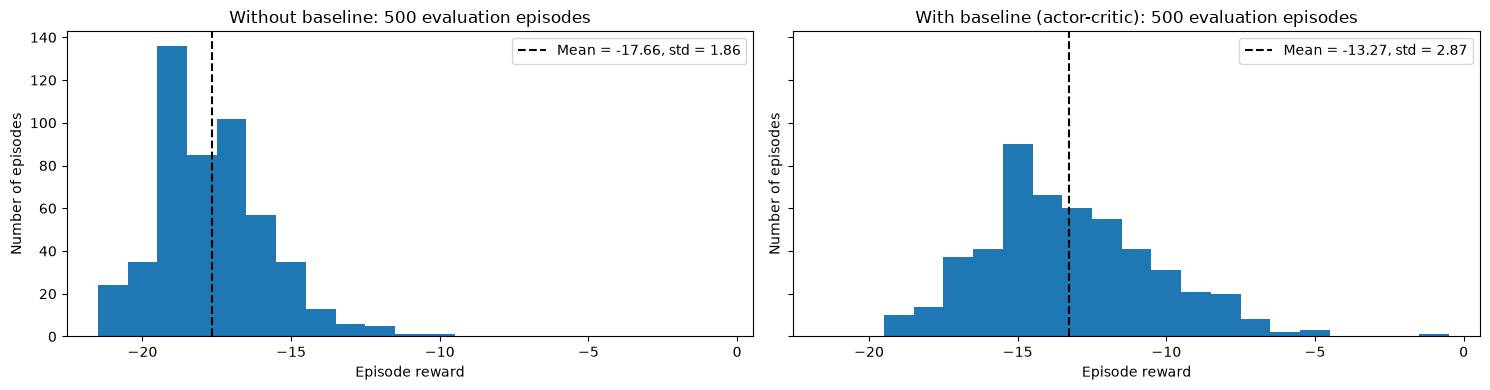

In [20]:
ac_eval = cached("eval_sampled", lambda: summary(evaluate(policy_act(ac_policy))))
np.save(CHECKPOINTS / AC_NAME / "eval_rewards.npy", ac_eval["reward"])
eval_rewards_by_run = {
    "Without baseline": np.load(CHECKPOINTS / PART1_NAME / "eval_rewards.npy"),
    "With baseline (actor-critic)": ac_eval["reward"],
}
greedy_by_run = {
    name: cached(
        f"eval_greedy_{run}",
        lambda run=run: summary(
            evaluate(
                policy_act(load_policy(run, EPISODES)),
                episodes=GREEDY_EPISODES,
                greedy=True,
            )
        ),
    )
    for name, run in RUN_TITLES.items()
}

bins = np.arange(-21.5, max(r.max() for r in eval_rewards_by_run.values()) + 1.5)
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, rewards) in zip(axes, eval_rewards_by_run.items()):
    mean, std = rewards.mean(), rewards.std()
    ax.hist(rewards, bins=bins)
    ax.axvline(
        mean, color="black", linestyle="--", label=f"Mean = {mean:.2f}, std = {std:.2f}"
    )
    ax.set(
        xlabel="Episode reward",
        ylabel="Number of episodes",
        title=f"{name}: {len(rewards)} evaluation episodes",
    )
    ax.legend(loc="upper right")
    print(f"{name}: mean = {mean:.2f}, std = {std:.2f}")
fig.tight_layout()
save_figure(fig, "baseline_histogram")
plt.show()

## Comparison: Without vs. With Baseline

**Expected:** with the baseline, the gradient is less noisy (Check 8), so the policy should start reacting to the ball
earlier and the reward should rise earlier and more steadily. Both runs see the same number of episodes and updates.

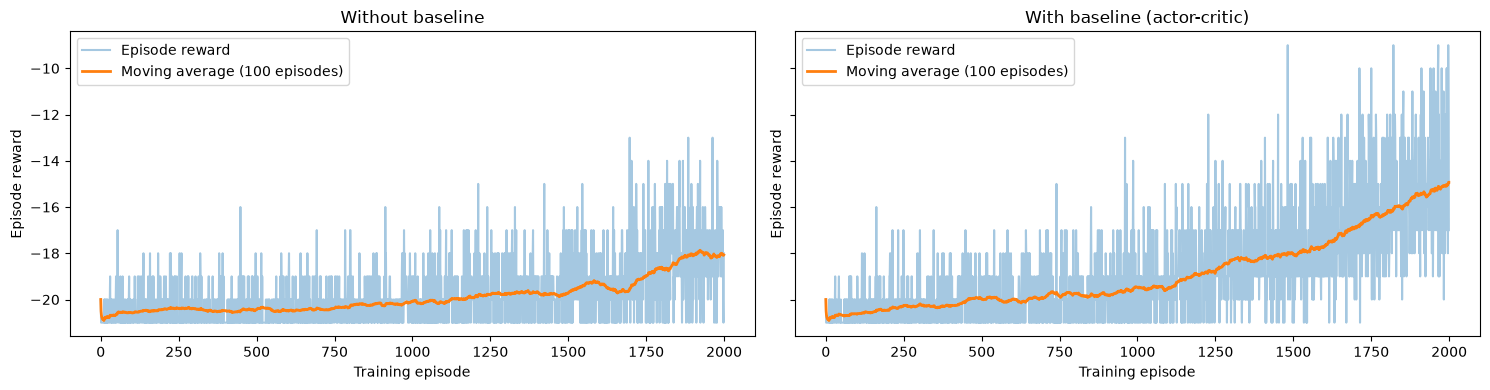

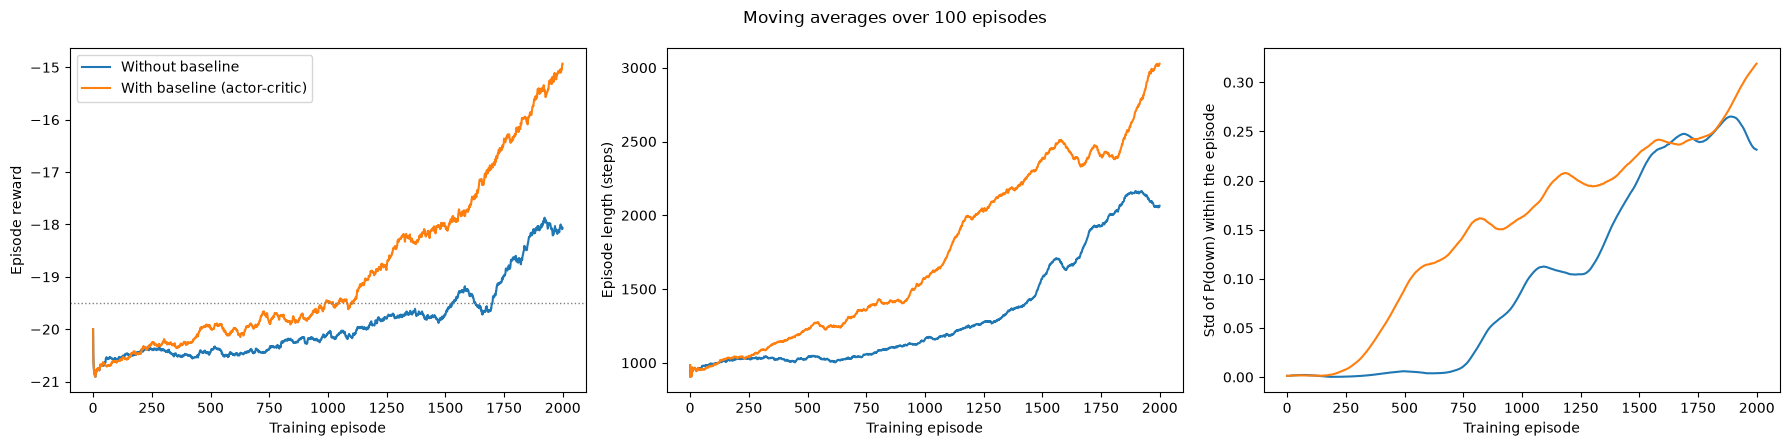

                                                  Without baseline    With baseline (actor-critic)
Mean training reward                                        -19.83                          -18.74
Reward, last 100 episodes                                   -18.07                          -14.93
Length, last 100 episodes                                     2065                            3028
Moving average reaches -19.5 at                               1530                             990
Evaluation, sampled (500)                            -17.66 ± 1.86                   -13.27 ± 2.87
Evaluation, greedy (50)                              -15.68 ± 2.37                   -10.22 ± 3.33
Greedy: points won / length                            5.32 / 2960                    10.78 / 3847


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, (name, log_) in zip(axes, logs.items()):
    plot_training(log_["reward"], name, ax=ax)
fig.tight_layout()
save_figure(fig, "baseline_training")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
panels = [
    ("reward", "Episode reward"),
    ("length", "Episode length (steps)"),
    ("p_down_std", "Std of P(down) within the episode"),
]
for ax, (key, label) in zip(axes, panels):
    for name, log_ in logs.items():
        ax.plot(moving_average(log_[key]), label=name)
    ax.set(xlabel="Training episode", ylabel=label)
axes[0].axhline(REWARD_LEVEL, color="gray", linestyle=":", linewidth=1)
axes[0].legend()
fig.suptitle(f"Moving averages over {MOVING_AVERAGE_WINDOW} episodes")
fig.tight_layout()
save_figure(fig, "baseline_comparison")
plt.show()


def first_episode_reaching(rewards, level: float = REWARD_LEVEL) -> int | None:
    """First episode at which the full-window moving average reaches `level`."""
    average = moving_average(rewards)[MOVING_AVERAGE_WINDOW - 1 :]
    hits = np.flatnonzero(average >= level)
    return int(hits[0]) + MOVING_AVERAGE_WINDOW if hits.size else None


print(f"{'':<34}" + "".join(f"{name:>32}" for name in logs))
rows = {
    "Mean training reward": lambda n: f"{logs[n]['reward'].mean():.2f}",
    "Reward, last 100 episodes": lambda n: f"{logs[n]['reward'][-100:].mean():.2f}",
    "Length, last 100 episodes": lambda n: f"{logs[n]['length'][-100:].mean():.0f}",
    f"Moving average reaches {REWARD_LEVEL} at": lambda n: str(
        first_episode_reaching(logs[n]["reward"]) or "never"
    ),
    f"Evaluation, sampled ({EVAL_EPISODES})": lambda n: (
        f"{eval_rewards_by_run[n].mean():.2f} ± {eval_rewards_by_run[n].std():.2f}"
    ),
    f"Evaluation, greedy ({GREEDY_EPISODES})": lambda n: (
        f"{greedy_by_run[n]['reward'].mean():.2f} ± {greedy_by_run[n]['reward'].std():.2f}"
    ),
    "Greedy: points won / length": lambda n: (
        f"{greedy_by_run[n]['won'].mean():.2f} / {greedy_by_run[n]['length'].mean():.0f}"
    ),
}
for label, value in rows.items():
    print(f"{label:<34}" + "".join(f"{value(name):>32}" for name in logs))

### What the Critic Learns

- **Critic loss** and **explained variance** $1 - \mathrm{Var}(G - V) / \mathrm{Var}(G)$ per episode: 0 means the critic only
  predicts the average return, 1 means it predicts every return exactly.
- **Mean $|A_t|$ vs. mean $|G_t|$:** how much smaller the weights of the actor's update are with the baseline.

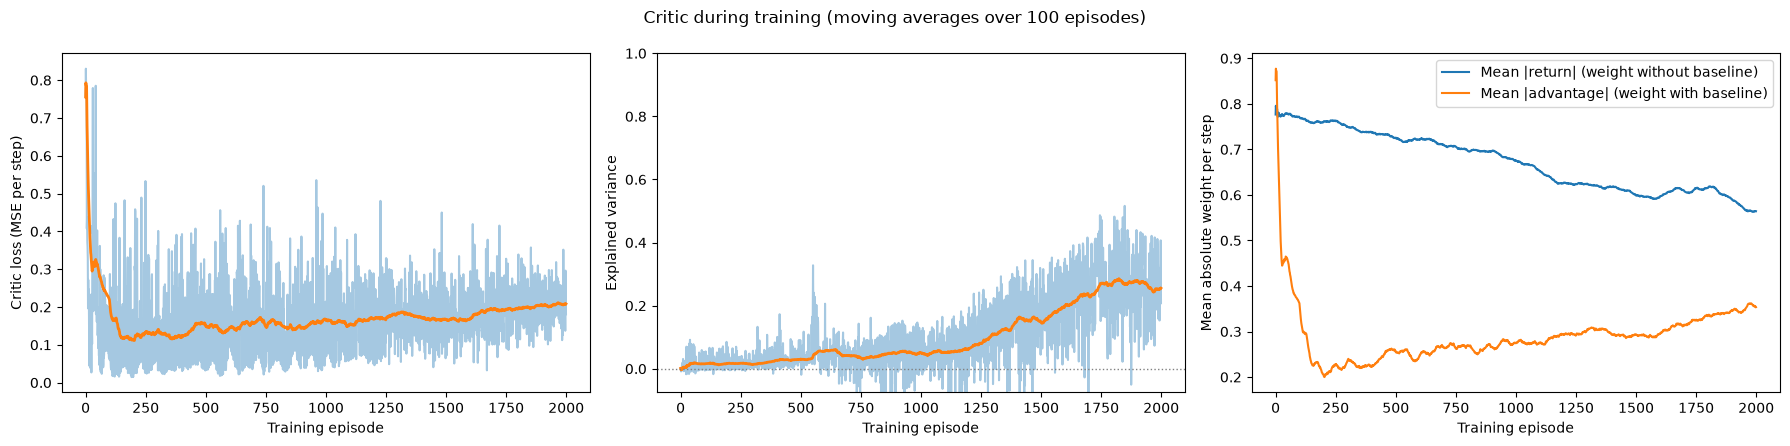

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (key, label) in zip(
    axes[:2],
    [
        ("value_loss", "Critic loss (MSE per step)"),
        ("explained_variance", "Explained variance"),
    ],
):
    ax.plot(ac_log[key], alpha=0.4)
    ax.plot(moving_average(ac_log[key]), linewidth=2)
    ax.set(xlabel="Training episode", ylabel=label)
axes[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[1].set_ylim(max(-1, np.percentile(ac_log["explained_variance"], 1)), 1)
axes[2].plot(
    moving_average(ac_log["return_abs"]),
    label="Mean |return| (weight without baseline)",
)
axes[2].plot(
    moving_average(ac_log["advantage_abs"]),
    label="Mean |advantage| (weight with baseline)",
)
axes[2].set(xlabel="Training episode", ylabel="Mean absolute weight per step")
axes[2].legend()
fig.suptitle("Critic during training (moving averages over 100 episodes)")
fig.tight_layout()
save_figure(fig, "baseline_critic")
plt.show()

### Policy Response: Without vs. With Baseline

The direction and position gaps of Part 1, Check 4, for the checkpoints of both runs (8 episodes each). **Expected:** with
the baseline, the direction gap appears earlier. The critic sees the paddle's position, so a position gap may appear as well.

100%|██████████| 8/8 [00:31<00:00,  3.99s/it]


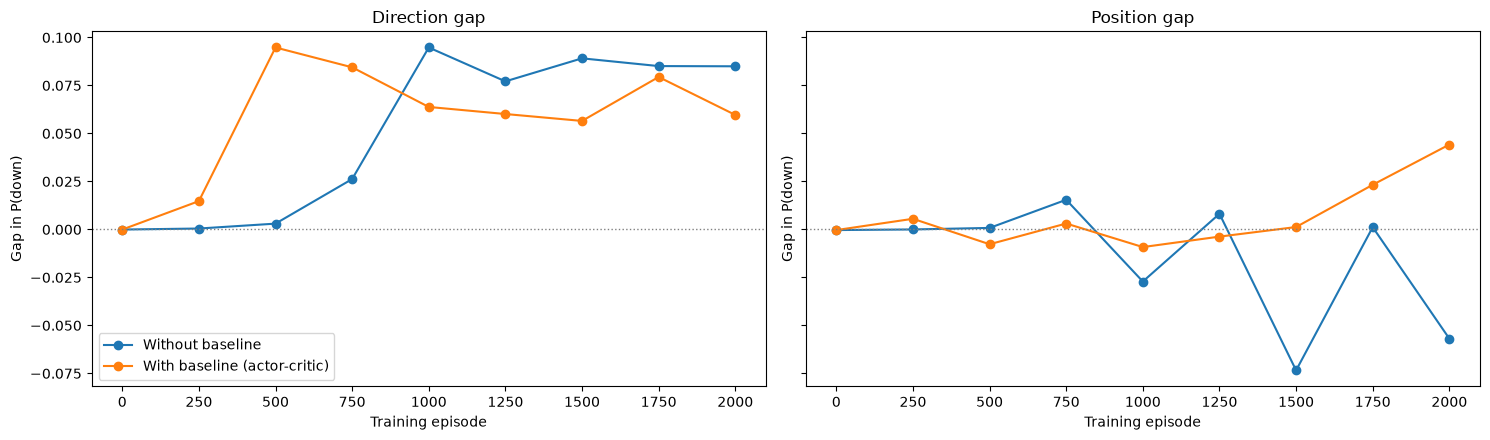

Checkpoint       Without baseline: dir / pos       With baseline (a: dir / pos
         0                  -0.000 / -0.000                  -0.000 / -0.000
       250                  +0.000 / -0.000                  +0.015 / +0.006
       500                  +0.003 / +0.001                  +0.095 / -0.008
       750                  +0.026 / +0.015                  +0.084 / +0.003
      1000                  +0.095 / -0.027                  +0.064 / -0.009
      1250                  +0.077 / +0.008                  +0.060 / -0.004
      1500                  +0.089 / -0.073                  +0.057 / +0.001
      1750                  +0.085 / +0.001                  +0.079 / +0.023
      2000                  +0.085 / -0.057                  +0.060 / +0.044


In [23]:
responses_by_run = {
    name: cached(
        f"response_{run}",
        lambda run=run: {
            episode: response(
                evaluate(
                    policy_act(load_policy(run, episode)), episodes=RESPONSE_EPISODES
                )
            )
            for episode in CHECKPOINT_EPISODES
        },
    )
    for name, run in RUN_TITLES.items()
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, key in zip(axes, ("direction gap", "position gap")):
    for name, responses_ in responses_by_run.items():
        ax.plot(
            CHECKPOINT_EPISODES,
            [responses_[e][key] for e in CHECKPOINT_EPISODES],
            marker="o",
            label=name,
        )
    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="Training episode", ylabel="Gap in P(down)", title=key.capitalize())
axes[0].legend()
fig.tight_layout()
save_figure(fig, "baseline_policy_response")
plt.show()

print(
    f"{'Checkpoint':>10}"
    + "".join(f"{name[:16] + ': dir / pos':>34}" for name in responses_by_run)
)
for episode in CHECKPOINT_EPISODES:
    print(
        f"{episode:>10}"
        + "".join(
            f"{r[episode]['direction gap']:>+24.3f} / {r[episode]['position gap']:+.3f}"
            for r in responses_by_run.values()
        )
    )

## Part 2 Checks

### Check 6: Fair Setup and Advantage Computation

**Expected:**
- The actor starts from exactly the same weights as in Part 1, and the first batch of 5 episodes (before the first update)
  is identical to Part 1. Any later difference is caused by the baseline.
- The values in the advantage carry no gradient, so the actor's loss cannot train the critic.
- The critic's chunked forward/backward pass gives the same values, loss and gradients as a single pass.
- Explained variance is 1 for a perfect critic and 0 for one that predicts the mean return.

In [24]:
initial_part1, initial_ac = (
    load_policy(PART1_NAME, 0).state_dict(),
    load_policy(AC_NAME, 0).state_dict(),
)
report(
    "Same initial actor weights as in Part 1",
    all(torch.equal(initial_part1[key], initial_ac[key]) for key in initial_part1),
)
first = slice(0, BATCH_EPISODES)
report(
    f"The first {BATCH_EPISODES} episodes are identical to Part 1 (rewards {ac_log['reward'][first].tolist()})",
    np.array_equal(part1_log["reward"][first], ac_log["reward"][first])
    and np.array_equal(part1_log["length"][first], ac_log["length"][first]),
)

torch.manual_seed(SEED)
critic = Critic()
inputs = torch.randint(-1, 2, (50, 2, 80, 80), dtype=torch.int8)
returns = torch.linspace(-1, 1, 50)
gradients = {}
for chunk in (7, 1000):
    critic.zero_grad()
    values, loss = critic_values(critic, inputs, returns, chunk=chunk)
    gradients[chunk] = (values, loss, [p.grad.clone() for p in critic.parameters()])
report(
    "The values in the advantage carry no gradient", not gradients[7][0].requires_grad
)
(v7, l7, g7), (v_all, l_all, g_all) = gradients[7], gradients[1000]
report(
    "Chunked critic pass (7 steps) = single pass: same values, loss and gradients",
    torch.allclose(v7, v_all, atol=1e-6)
    and np.isclose(l7, l_all)
    and all(torch.allclose(a, b, atol=1e-6) for a, b in zip(g7, g_all)),
)
report(
    "Explained variance: 1 for V = G, 0 for V = mean(G)",
    np.isclose(explained_variance(returns, returns), 1)
    and np.isclose(
        explained_variance(returns, returns.mean().expand(50)), 0, atol=1e-6
    ),
)

[PASS] Same initial actor weights as in Part 1
[PASS] The first 5 episodes are identical to Part 1 (rewards [-20.0, -21.0, -21.0, -21.0, -21.0])
[PASS] The values in the advantage carry no gradient
[PASS] Chunked critic pass (7 steps) = single pass: same values, loss and gradients
[PASS] Explained variance: 1 for V = G, 0 for V = mean(G)


### Check 7: Does the Critic Predict the Return?

10 episodes of the final actor. On the same steps, I compare the untrained critic (episode 0) with the final one.
**Expected:**
- The final critic explains a clearly positive share of the variance of $G_t$; the untrained one does not (≈ 0 or below).
- Shortly before a point, $V$ is higher when the agent is about to win the point than when it is about to lose it.
- Calibration: steps with a higher $V$ have a higher average return.

100%|██████████| 10/10 [00:57<00:00,  5.76s/it]


Explained variance: initial critic +0.000, final critic +0.325
Mean return -0.249, mean V (final critic) -0.437
Mean V over the last 20 steps before a point: won (91) +0.099, lost (210) -0.605
[PASS] The final critic explains part of the return's variance (explained variance > 0)
[PASS] The final critic predicts better than the untrained one
[PASS] V is higher before a won point than before a lost point


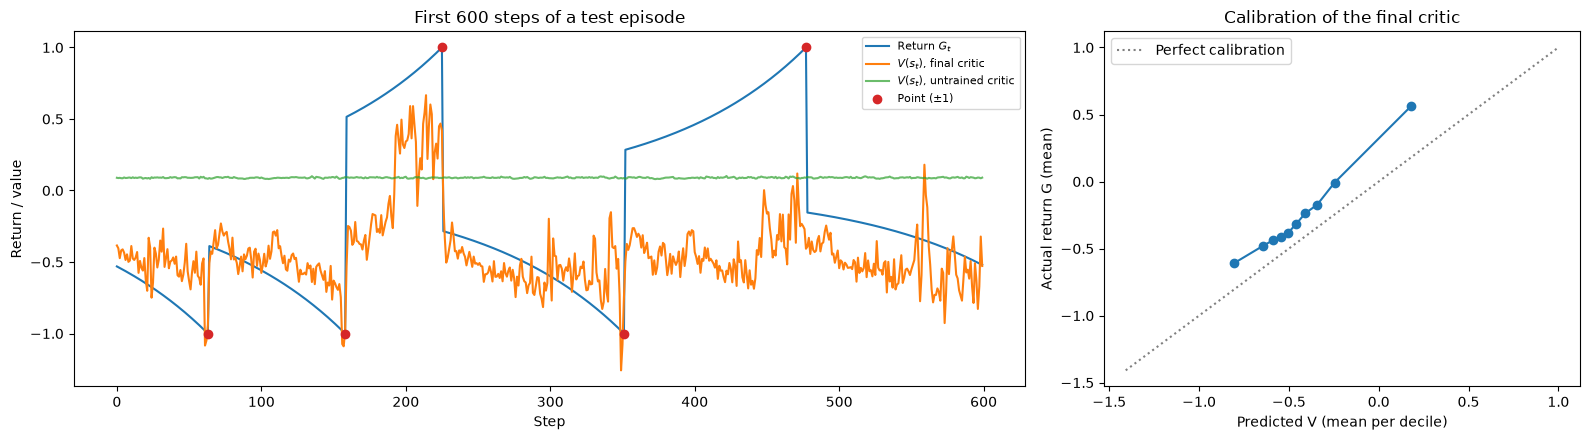

In [25]:
POINT_WINDOW = 20  # steps before a point


def value_traces(
    policy: nn.Module,
    critics: dict[str, nn.Module],
    episodes: int = VALUE_EPISODES,
    seed: int = SEED,
) -> list[dict]:
    """Rewards, returns and the values of every critic for `episodes` episodes of `policy` (episode i from seed + i)."""
    env = gym.make("ALE/Pong-v5")
    torch.manual_seed(seed)
    traces = []
    for i in tqdm(range(episodes)):
        with torch.no_grad():
            sample = sample_episode(env, policy, seed=seed + i)
        trace = {
            "rewards": np.array(sample["rewards"]),
            "returns": rewards_to_returns(sample["rewards"], GAMMA).numpy(),
        }
        for label, critic in critics.items():
            trace[label] = critic_values(critic, sample["inputs"])[0].numpy()
        traces.append(trace)
    env.close()
    return traces


traces = cached(
    "value_traces",
    lambda: value_traces(
        load_policy(AC_NAME, EPISODES),
        {"initial": load_critic(AC_NAME, 0), "final": load_critic(AC_NAME, EPISODES)},
    ),
)
returns = np.concatenate([t["returns"] for t in traces])
values = {
    label: np.concatenate([t[label] for t in traces]) for label in ("initial", "final")
}
ev = {
    label: explained_variance(torch.tensor(returns), torch.tensor(v))
    for label, v in values.items()
}

before = {"won": [], "lost": []}
for t in traces:
    for step in np.flatnonzero(t["rewards"]):
        before["won" if t["rewards"][step] > 0 else "lost"].append(
            t["final"][max(0, step - POINT_WINDOW) : step + 1].mean()
        )
mean_before = {key: np.mean(v) if v else np.nan for key, v in before.items()}

print(
    f"Explained variance: initial critic {ev['initial']:+.3f}, final critic {ev['final']:+.3f}"
)
print(
    f"Mean return {returns.mean():+.3f}, mean V (final critic) {values['final'].mean():+.3f}"
)
print(
    f"Mean V over the last {POINT_WINDOW} steps before a point: won ({len(before['won'])}) {mean_before['won']:+.3f}, "
    f"lost ({len(before['lost'])}) {mean_before['lost']:+.3f}"
)
report(
    "The final critic explains part of the return's variance (explained variance > 0)",
    ev["final"] > 0,
)
report(
    "The final critic predicts better than the untrained one",
    ev["final"] > ev["initial"],
)
report(
    "V is higher before a won point than before a lost point",
    mean_before["won"] > mean_before["lost"],
)

fig, (ax_t, ax_c) = plt.subplots(
    1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]}
)
t = traces[0]
steps = slice(0, 600)
ax_t.plot(t["returns"][steps], label="Return $G_t$")
ax_t.plot(t["final"][steps], label="$V(s_t)$, final critic")
ax_t.plot(t["initial"][steps], label="$V(s_t)$, untrained critic", alpha=0.7)
points = np.flatnonzero(t["rewards"][steps])
ax_t.scatter(
    points, t["rewards"][steps][points], color="C3", zorder=3, label="Point (±1)"
)
ax_t.set(
    xlabel="Step", ylabel="Return / value", title="First 600 steps of a test episode"
)
ax_t.legend(fontsize=8)
edges = np.quantile(values["final"], np.linspace(0, 1, 11))
which = np.clip(np.digitize(values["final"], edges[1:-1]), 0, 9)
ax_c.plot(
    [values["final"][which == b].mean() for b in range(10)],
    [returns[which == b].mean() for b in range(10)],
    marker="o",
)
lims = [
    min(returns.min(), values["final"].min()),
    max(returns.max(), values["final"].max()),
]
ax_c.plot(lims, lims, color="gray", linestyle=":", label="Perfect calibration")
ax_c.set(
    xlabel="Predicted V (mean per decile)",
    ylabel="Actual return G (mean)",
    title="Calibration of the final critic",
)
ax_c.legend()
fig.tight_layout()
save_figure(fig, "baseline_values")
plt.show()

### Check 8: Variance of the Gradient Estimate

A baseline should reduce the variance of the policy-gradient estimate without changing its expected value. As in CartPole
(Part 2, Check 8): for a **fixed** actor and critic, I sample 20 batches of 5 episodes and compute every batch's gradient
on the same episodes three times: without baseline, with a constant baseline (mean return of the batch) and with the critic.
The total variance is $\frac{1}{M}\sum_m \lVert g_m - \bar g \rVert^2$. I do this for the initial and the final checkpoint
of the actor-critic run, each with its own critic. The entropy term is left out. **Expected:**
- Final checkpoint: clearly lower variance with the critic.
- Initial checkpoint: the untrained critic predicts almost a constant, so it helps at most about as much as the constant baseline.
- The mean gradients with and without baseline point in a similar direction (unbiased). With 20 batches this is only a rough check.

About 15 minutes; the result is cached.

In [ ]:
BASELINE_LABELS = ["No baseline", "Constant (batch mean)", "Critic V(s)"]


def flat_grad(
    loss: torch.Tensor, parameters, retain_graph: bool = False
) -> torch.Tensor:
    return torch.cat(
        [
            g.flatten()
            for g in torch.autograd.grad(loss, parameters, retain_graph=retain_graph)
        ]
    )


def gradient_statistics(
    policy: nn.Module,
    critic: nn.Module,
    batches: int = GRADIENT_BATCHES,
    seed: int = SEED,
) -> dict:
    """Total variance of the batch gradient and cosine of its mean with the mean gradient without baseline, per baseline."""
    env = gym.make("ALE/Pong-v5")
    torch.manual_seed(seed)
    env.reset(seed=seed)
    parameters = list(policy.parameters())
    gradients = {label: [] for label in BASELINE_LABELS}
    for _ in tqdm(range(batches)):
        g_returns, g_ones, g_values, batch_returns = 0, 0, 0, []
        for _ in range(BATCH_EPISODES):
            sample = sample_episode(env, policy)
            returns = rewards_to_returns(sample["rewards"], GAMMA)
            values, _ = critic_values(critic, sample["inputs"])
            log_probs = sample["log_probs"]
            # The loss is linear in the weights of the log-probabilities, so every baseline is a combination of these three gradients
            g_returns = g_returns + flat_grad(
                -(log_probs * returns).sum(), parameters, retain_graph=True
            )
            g_ones = g_ones + flat_grad(-log_probs.sum(), parameters, retain_graph=True)
            g_values = g_values + flat_grad(-(log_probs * values).sum(), parameters)
            batch_returns.append(returns)
        b = torch.cat(batch_returns).mean()
        gradients["No baseline"].append(g_returns)
        gradients["Constant (batch mean)"].append(g_returns - b * g_ones)
        gradients["Critic V(s)"].append(g_returns - g_values)
    env.close()

    stacked = {label: torch.stack(g) for label, g in gradients.items()}
    reference = stacked["No baseline"].mean(dim=0)
    return {
        label: {
            "variance": ((g - g.mean(dim=0)) ** 2).sum(dim=1).mean().item(),
            "cosine": torch.nn.functional.cosine_similarity(
                g.mean(dim=0), reference, dim=0
            ).item(),
        }
        for label, g in stacked.items()
    }


gradient_stats = {
    f"After {episode} episodes": cached(
        f"gradient_statistics_{episode}",
        lambda episode=episode: gradient_statistics(
            load_policy(AC_NAME, episode), load_critic(AC_NAME, episode)
        ),
    )
    for episode in (0, EPISODES)
}

print(
    f"{'Checkpoint':<24}{'Baseline':<24}{'Variance':>12}{'vs. none':>10}{'cos(mean, none)':>17}"
)
for checkpoint, stats in gradient_stats.items():
    for label, s in stats.items():
        print(
            f"{checkpoint:<24}{label:<24}{s['variance']:>12.3g}{s['variance'] / stats['No baseline']['variance']:>10.3f}{s['cosine']:>17.3f}"
        )
final_stats = gradient_stats[f"After {EPISODES} episodes"]
report(
    "Final checkpoint: the critic reduces the gradient variance",
    final_stats["Critic V(s)"]["variance"] < final_stats["No baseline"]["variance"],
)
report(
    "Final checkpoint: the critic reduces the variance more than the constant baseline",
    final_stats["Critic V(s)"]["variance"]
    < final_stats["Constant (batch mean)"]["variance"],
)

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(BASELINE_LABELS)
for k, label in enumerate(BASELINE_LABELS):
    ax.bar(
        np.arange(len(gradient_stats)) + k * width,
        [s[label]["variance"] for s in gradient_stats.values()],
        width,
        label=label,
    )
ax.set_xticks(
    np.arange(len(gradient_stats)) + width * (len(BASELINE_LABELS) - 1) / 2,
    list(gradient_stats),
)
ax.set(
    yscale="log",
    ylabel="Total variance of the gradient",
    title=f"Gradient variance over {GRADIENT_BATCHES} batches of {BATCH_EPISODES} episodes (actor-critic run)",
)
ax.legend()
save_figure(fig, "baseline_gradient_variance")
plt.show()

 90%|█████████ | 18/20 [17:09<02:04, 62.11s/it]

### Part 2 Edge-Case Checks
- **Invalid inputs:** as in Part 1, plus a critic optimizer that does not optimize the critic's parameters, which would
  silently leave the critic untrained.
- **Reproducibility:** training twice with the same seed gives identical results, including the critic.
- **Value range:** with the return restart after every point, $G_t \in [-1, 1]$. The critic's output is not bounded, so I
  check how often its predictions in Check 7 leave this range.

In [ ]:
env = gym.make("ALE/Pong-v5")
policy, critic = Policy(), Critic()
invalid = {
    "episodes = 0": {"episodes": 0, "gamma": GAMMA},
    "γ = 0": {"episodes": 1, "gamma": 0.0},
    "batch_episodes = 0": {"episodes": 1, "gamma": GAMMA, "batch_episodes": 0},
    "a critic optimizer of another network": {
        "episodes": 1,
        "gamma": GAMMA,
        "critic_optimizer": optim.Adam(Critic().parameters()),
    },
}
for label, kwargs in invalid.items():
    critic_optimizer = kwargs.pop("critic_optimizer", optim.Adam(critic.parameters()))
    try:
        train_actor_critic(
            env,
            policy,
            critic,
            optim.Adam(policy.parameters()),
            critic_optimizer,
            **kwargs,
        )
        raised = False
    except ValueError:
        raised = True
    report(f"Rejects {label}", raised)


def short_actor_critic_run() -> dict[str, np.ndarray]:
    torch.manual_seed(SEED)
    policy = Policy()
    with torch.random.fork_rng(devices=[]):
        critic = Critic()
    return train_actor_critic(
        env,
        policy,
        critic,
        optim.Adam(policy.parameters(), lr=LEARNING_RATE),
        optim.Adam(critic.parameters(), lr=CRITIC_LEARNING_RATE),
        2,
        GAMMA,
        batch_episodes=1,
        seed=SEED,
    )


first, second = short_actor_critic_run(), short_actor_critic_run()
report(
    "Same seed gives identical training (including the critic's loss)",
    all(np.array_equal(first[key], second[key]) for key in first),
)
env.close()

outside = np.mean(np.abs(values["final"]) > 1)
print(f"Share of the final critic's predictions outside [-1, 1]: {outside:.2%}")

# Simulation

One game of the trained policy in a window (the player is the green paddle on the right). The policy is loaded from
the final checkpoint, so after a kernel restart only the definition cells (up to *Evaluation and Plotting*) need to run
first, not the training or the evaluation. A full game takes a few minutes; interrupting the cell closes the window.

In [ ]:
GREEDY = (
    True  # True: always take the more likely action, which plays better (see Check 3)
)

RUN = "actor_critic"  # "reinforce" (Part 1) or "actor_critic" (Part 2)

trained_policy = load_policy(RUN, EPISODES)  # final checkpoint, no training needed
simulation = gym.make("ALE/Pong-v5", render_mode="human")
try:
    episode = rollout(simulation, policy_act(trained_policy), seed=SEED, greedy=GREEDY)
    print(
        f"Reward {episode['reward'].sum():.0f}: won {np.sum(episode['reward'] == 1)}, "
        f"lost {np.sum(episode['reward'] == -1)} points in {len(episode['reward'])} steps"
    )
finally:
    simulation.close()

Reward -19: won 2, lost 21 points in 2480 steps
